## Ridge Regression

In [1]:
# Step 1: Importing the libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Step 2: Loading the dataset
df = pd.read_csv('Ridge_Regression_HousingData.csv')

In [4]:
# Step 3: Data Preprocessing
df.head()

,Unnamed: 0,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,Median House Value
0,0,3.9816,27.0,4.928668,1.122476,3009.0,4.049798,33.73,-117.93,1.795
1,1,3.4531,23.0,4.021339,1.099338,2511.0,1.847682,34.14,-118.13,2.109
2,2,6.3942,4.0,5.681272,1.095774,5613.0,2.176425,37.78,-121.95,3.567
3,3,2.2243,32.0,5.685221,1.009597,1542.0,2.959693,38.69,-121.45,0.892
4,4,3.0217,9.0,5.006324,1.071146,3265.0,2.581028,37.69,-121.04,1.609


In [5]:
# check the information about the datasets
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16512 entries, 0 to 16511
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Unnamed: 0          16512 non-null  int64  
 1   MedInc              16512 non-null  float64
 2   HouseAge            16512 non-null  float64
 3   AveRooms            16512 non-null  float64
 4   AveBedrms           16512 non-null  float64
 5   Population          16512 non-null  float64
 6   AveOccup            16512 non-null  float64
 7   Latitude            16512 non-null  float64
 8   Longitude           16512 non-null  float64
 9   Median House Value  16512 non-null  float64
dtypes: float64(9), int64(1)
memory usage: 1.3 MB


In [6]:
# check the missing value the in df
df.isnull().sum()

Unnamed: 0            0
MedInc                0
HouseAge              0
AveRooms              0
AveBedrms             0
Population            0
AveOccup              0
Latitude              0
Longitude             0
Median House Value    0
dtype: int64

In [7]:
# check the describe
df.describe()

,Unnamed: 0,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,Median House Value
count,16512.000000,16512.000000,16512.000000,16512.000000,16512.000000,16512.000000,16512.000000,16512.000000,16512.000000,16512.000000
mean,8255.500000,3.859050,28.592902,5.429562,1.096896,1429.927689,3.055425,35.632512,-119.565484,2.062298
std,4766.748158,1.887126,12.615380,2.552593,0.494423,1149.664255,10.780690,2.133356,1.998334,1.151592
min,0.000000,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,4127.750000,2.562500,18.000000,4.439906,1.006131,785.000000,2.430205,33.930000,-121.790000,1.189000
50%,8255.500000,3.531300,29.000000,5.227757,1.048689,1168.000000,2.814815,34.260000,-118.500000,1.786000
75%,12383.250000,4.725000,37.000000,6.051724,1.099955,1729.000000,3.278159,37.710000,-118.007500,2.646000
max,16511.000000,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.490000,5.000010


<Axes: >

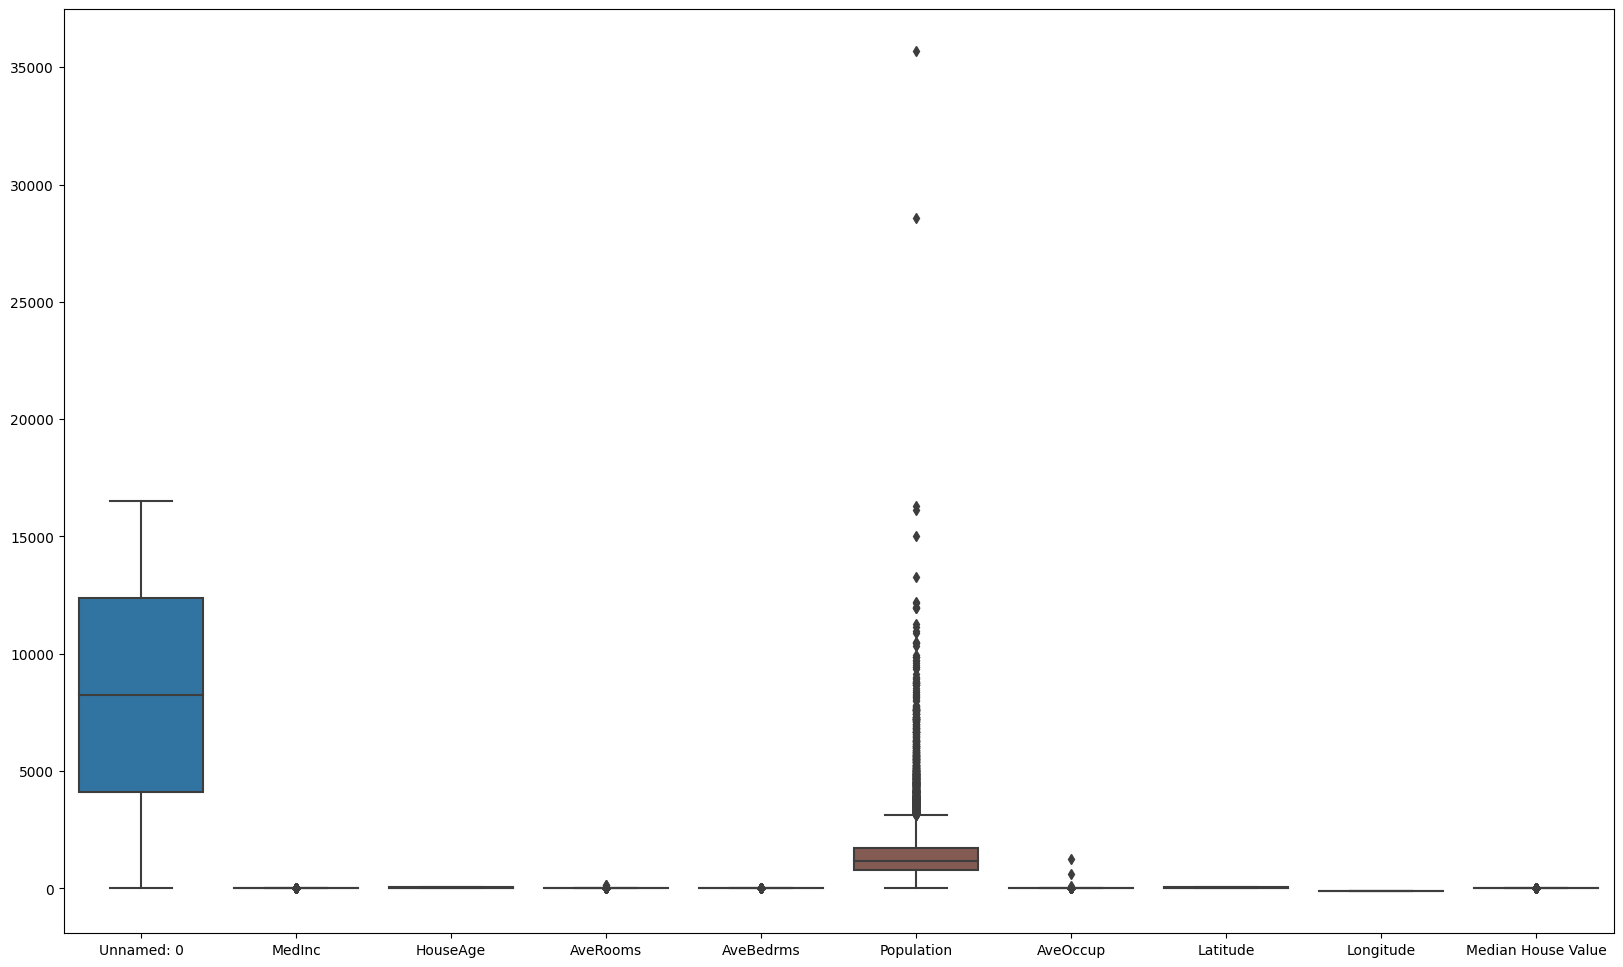

In [17]:
# Step 4: EDA

# make the box plot 

plt.figure(figsize=(20,12))
sns.boxplot(df)


In [19]:
# drop the Unnamed:0
df.drop(columns=['Unnamed: 0'],inplace=True)

In [25]:
# Handled the outlier using IQR with Clipping method
outlier_column  = df[['MedInc','AveRooms','AveBedrms','Population','AveOccup']]

for column in outlier_column.columns:

    # find the Q3
    Q3 = df[column].quantile(0.75)

    # Find the Q1
    Q1 = df[column].quantile(0.25)

    # find the IQR
    IQR = Q3 - Q1

    # Find lower Limit
    lower_limit = Q1 - 1.5 * IQR

    # Find upper Limit
    upper_limit = Q3 + 1.5 * IQR

    # Handled Outlier

    df[column]  = df[column].clip(lower=lower_limit,upper =upper_limit)
    



<Axes: >

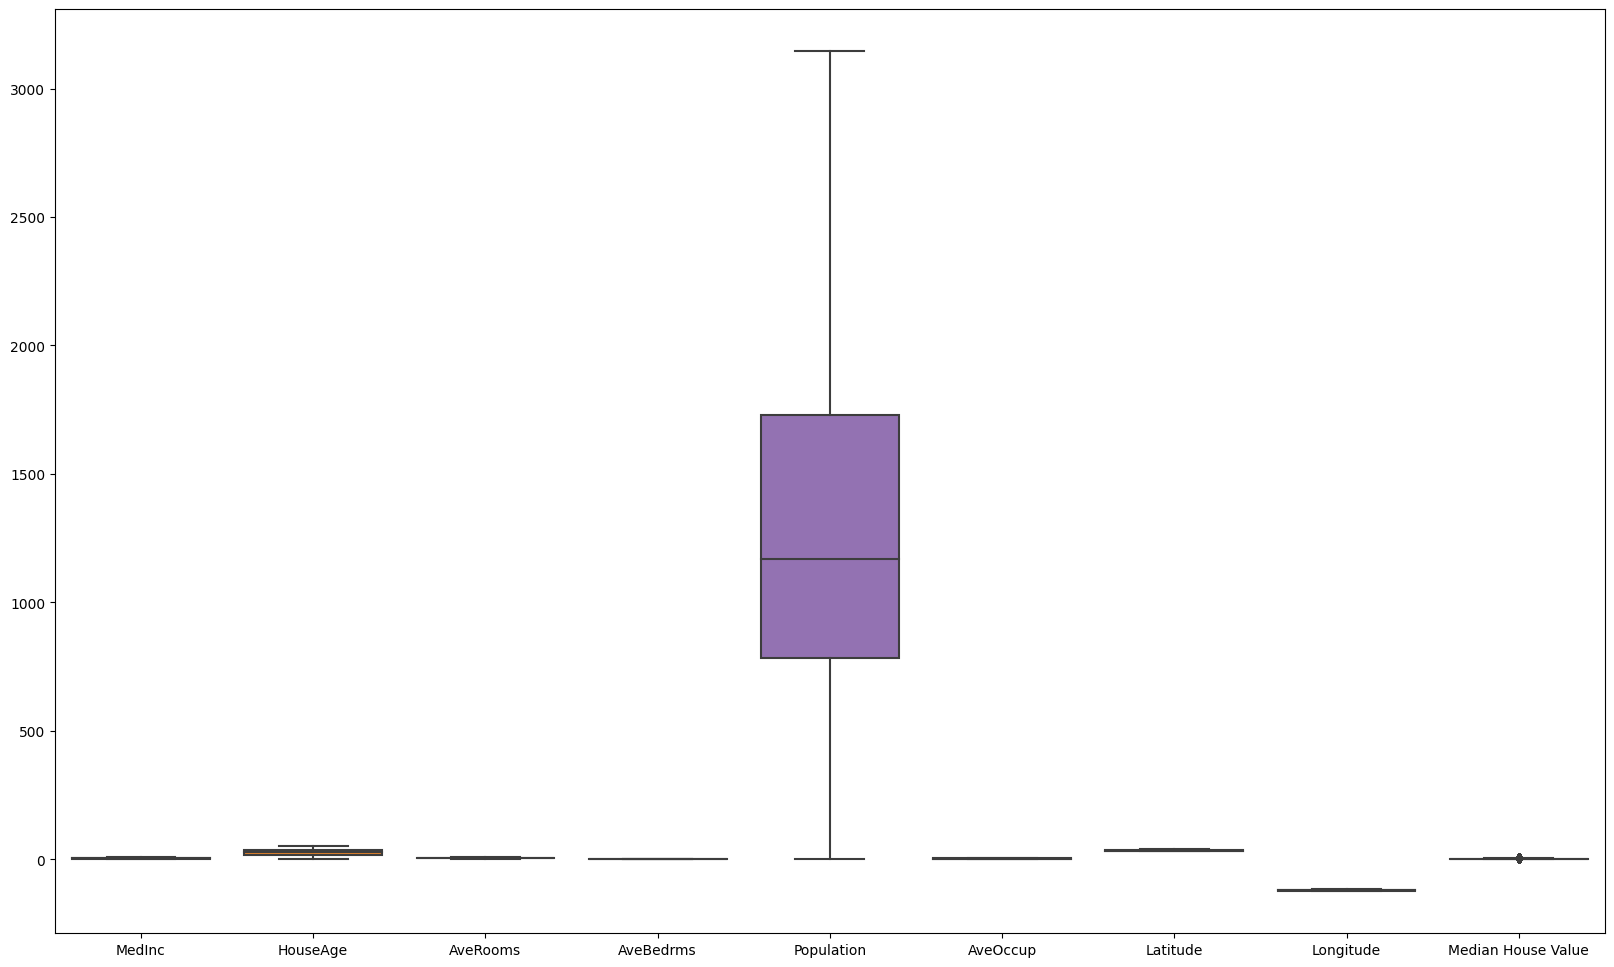